# Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import os
import glob
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, cross_val_score,GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPRegressor

warnings.filterwarnings('ignore')

# Reading Data

In [3]:
df1=pd.read_csv("C:\\Users\\dpree\\Desktop\\Kolate.AI\\1186\\Data\\Target_Lesion_Dataset1.csv")

In [4]:
df1.columns

Index(['Unnamed: 0', 'SUBJID', 'AGE', 'SEXCD', 'TRTDOSE', 'ATRT', 'PRBEVCD',
       'PROXACDR', 'PROXAM', 'PFSCR', 'PFSCRV', 'PDLR', 'TRTDUR', 'B_METANM',
       'KRAS', 'TUMCAT', 'LIVRONLY', 'PFSCR.1', 'PDLR.1', 'B_ALPNM', 'B_CEA',
       'B_CREAT', 'CDOSE_x', 'IRCDOSE', 'FBDUR', 'FBCDOSE', 'FIDUR', 'FICDOSE',
       'DIAGMONS_x', 'METMONS', 'BIOPTPCT', 'BIOPRS', 'CDOSE_y', 'DSDLYPC',
       'CHDLYNM', 'CHDLYPC', 'PROPDOSE', 'CHRESPCD', 'CHDRSNCD', 'CHTERM_5 FU',
       'CHTERM_5-FU', 'CHTERM_CAPECITABINE', 'CHTERM_LEUCOVORIN',
       'CHTERM_OXALIPLATIN', 'CHANY_Y', 'DTCAUSCD', 'DIAGMONS_y', 'BIOPACPT',
       'BIOPCYTO', 'PFUP', 'KRASCD', 'EVALITT_Y', 'EXDURMN', 'ACTTRTCD',
       'DOSE', 'LBSTRESN', 'LBSTNRLO', 'LBSTNRHI', 'LBORRESN', 'LBBLRES',
       'LBBASE_N', 'LBBASE_Y', 'DOSREFDY', 'min_DOSREFDY', 'min_LSSLD',
       'max_DOSREFDY', 'max_LSSLD', 'LSSLD_Diff', 'Percentage_LSSLD_Change',
       'LSSLD_Change', 'LPSUM_x', 'OTANY_N', 'OTANY_Y', 'RAANY_N', 'RAANY_Y',
       'RSNEW

In [5]:
df1.shape

(71644, 80)

In [6]:
df1['Set'] = df1['ATRT'].apply(lambda x: 'Control Arm' if x == 'FOLFIRI' else 'Treatment Arm')

In [7]:
df1['LSCAT']='Target Lesion'

In [8]:
df1['study_month'] = pd.cut(df1['max_DOSREFDY'], [df1['max_DOSREFDY'].min(),0,31,61,91,121,151,181,210,df1['max_DOSREFDY'].max()],labels = ['before_study','month1','month2','month3','month4','month5','month6','month7','>month7'])

In [9]:
df1.head()

,Unnamed: 0,SUBJID,AGE,SEXCD,TRTDOSE,ATRT,PRBEVCD,PROXACDR,PROXAM,PFSCR,...,RAANY_N,RAANY_Y,RSNEW_N,RSNEW_Y,SXANY_N,SXANY_Y,LPSUM_y,Set,LSCAT,study_month
0,0,201001001,54.0,M,6.0,Panitumumab + FOLFIRI,1.0,1.0,Y,1.0,...,1,0,1,1,0,1,NaN,Treatment Arm,Target Lesion,>month7
1,1,201001001,54.0,M,6.0,Panitumumab + FOLFIRI,1.0,1.0,Y,1.0,...,1,0,1,1,0,1,NaN,Treatment Arm,Target Lesion,>month7
2,2,201001001,54.0,M,6.0,Panitumumab + FOLFIRI,1.0,1.0,Y,1.0,...,1,0,1,1,0,1,NaN,Treatment Arm,Target Lesion,>month7
3,3,201001001,54.0,M,6.0,Panitumumab + FOLFIRI,1.0,1.0,Y,1.0,...,1,0,1,1,0,1,NaN,Treatment Arm,Target Lesion,>month7
4,4,201001001,54.0,M,6.0,Panitumumab + FOLFIRI,1.0,1.0,Y,1.0,...,1,0,1,1,0,1,NaN,Treatment Arm,Target Lesion,>month7


# Feature Selection by Random Forest

In [11]:
df=df1

In [12]:
df = pd.get_dummies(df1, drop_first=True)

In [13]:
df.fillna(0, inplace=True)

In [14]:
# Separate features and target
X = df.drop('LSSLD_Change', axis=1)
y = df['LSSLD_Change']

In [15]:
# Train a Random Forest model
rf = RandomForestClassifier(random_state=42)
rf.fit(X, y)

RandomForestClassifier(random_state=42)

In [16]:
importances = rf.feature_importances_

In [17]:
# Create a dataframe for feature importances
feature_importances_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feature_importances_df = feature_importances_df.sort_values(by='Importance', ascending=False)

In [18]:
feature_importances_df.head(50)

,Feature,Importance
60,Percentage_LSSLD_Change,0.488214
59,LSSLD_Diff,0.200181
58,max_LSSLD,0.050815
56,min_LSSLD,0.041741
57,max_DOSREFDY,0.010709
17,IRCDOSE,0.010567
9,TRTDUR,0.009317
21,FICDOSE,0.008566
18,FBDUR,0.007360
46,DOSE,0.006670


# Forming New Dataset

In [21]:
df1=df1[['SUBJID','DOSREFDY','Percentage_LSSLD_Change','LSSLD_Change','LSCAT','IRCDOSE','TRTDUR','FICDOSE','LBORRESN','METMONS','B_CEA','LBSTRESN','PFUP','DOSE','B_CREAT','CDOSE_x','LBSTNRLO','FIDUR','FBDUR','FBCDOSE','B_ALPNM','EXDURMN','LBBLRES','CDOSE_y','DIAGMONS_x','LBSTNRHI','BIOPTPCT','DTCAUSCD','DSDLYPC','AGE','CHDLYPC','PROPDOSE','Set','study_month']]
df1.shape

(71644, 34)

In [22]:
df1.head()

,SUBJID,DOSREFDY,Percentage_LSSLD_Change,LSSLD_Change,LSCAT,IRCDOSE,TRTDUR,FICDOSE,LBORRESN,METMONS,...,DIAGMONS_x,LBSTNRHI,BIOPTPCT,DTCAUSCD,DSDLYPC,AGE,CHDLYPC,PROPDOSE,Set,study_month
0,201001001,NaN,63.703704,1.0,Target Lesion,5804.98,219.0,77418.0,41.818998,9.540984,...,9.540984,75.074683,61.28,7.0,0.0625,54.0,0.0625,3.041537,Treatment Arm,>month7
1,201001001,-15.0,63.703704,1.0,Target Lesion,5804.98,219.0,77418.0,41.818998,9.540984,...,9.540984,75.074683,61.28,7.0,0.0625,54.0,0.0625,3.041537,Treatment Arm,>month7
2,201001001,-15.0,63.703704,1.0,Target Lesion,5804.98,219.0,77418.0,41.818998,9.540984,...,9.540984,75.074683,61.28,7.0,0.0625,54.0,0.0625,3.041537,Treatment Arm,>month7
3,201001001,-15.0,63.703704,1.0,Target Lesion,5804.98,219.0,77418.0,41.818998,9.540984,...,9.540984,75.074683,61.28,7.0,0.0625,54.0,0.0625,3.041537,Treatment Arm,>month7
4,201001001,-15.0,63.703704,1.0,Target Lesion,5804.98,219.0,77418.0,41.818998,9.540984,...,9.540984,75.074683,61.28,7.0,0.0625,54.0,0.0625,3.041537,Treatment Arm,>month7


In [23]:
df1.columns

Index(['SUBJID', 'DOSREFDY', 'Percentage_LSSLD_Change', 'LSSLD_Change',
       'LSCAT', 'IRCDOSE', 'TRTDUR', 'FICDOSE', 'LBORRESN', 'METMONS', 'B_CEA',
       'LBSTRESN', 'PFUP', 'DOSE', 'B_CREAT', 'CDOSE_x', 'LBSTNRLO', 'FIDUR',
       'FBDUR', 'FBCDOSE', 'B_ALPNM', 'EXDURMN', 'LBBLRES', 'CDOSE_y',
       'DIAGMONS_x', 'LBSTNRHI', 'BIOPTPCT', 'DTCAUSCD', 'DSDLYPC', 'AGE',
       'CHDLYPC', 'PROPDOSE', 'Set', 'study_month'],
      dtype='object')

In [27]:
dataset_month2 = df1[df1['study_month'] == 'month2']
dataset_month1 = df1[(df1['study_month'] == 'month1') | (df1['study_month'] == 'before_study')]

In [33]:
dataset_month1.shape

(1723, 34)

In [34]:
dataset_month2.shape

(7169, 34)

# Regression For Target Lesions LSSLD

# Month 1

# Logistic Regression

In [41]:
result=dataset_month1

In [42]:
X=result[['IRCDOSE','TRTDUR','FICDOSE','LBORRESN','METMONS','B_CEA','LBSTRESN','PFUP','DOSE','B_CREAT','CDOSE_x','LBSTNRLO','FIDUR','FBDUR','FBCDOSE','B_ALPNM','EXDURMN','LBBLRES','CDOSE_y','DIAGMONS_x','LBSTNRHI','BIOPTPCT','DTCAUSCD','DSDLYPC','AGE','CHDLYPC','PROPDOSE']]
y=result[['LSSLD_Change']]
X.fillna(0,inplace=True)
y.fillna(0,inplace=True)

In [43]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [44]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [45]:
model11= LogisticRegression()

In [46]:
model11.fit(X_train_scaled, y_train)

LogisticRegression()

In [47]:
y_pred = model11.predict(X_test_scaled)

In [48]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.8348


In [49]:
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(conf_matrix)

Confusion Matrix:
[[ 95  30]
 [ 27 193]]


In [50]:
class_report = classification_report(y_test, y_pred)
print("Classification Report:")
print(class_report)

Classification Report:
              precision    recall  f1-score   support

         0.0       0.78      0.76      0.77       125
         1.0       0.87      0.88      0.87       220

    accuracy                           0.83       345
   macro avg       0.82      0.82      0.82       345
weighted avg       0.83      0.83      0.83       345



In [51]:
y_train_pred = model11.predict(X_train_scaled)

y_test_pred = model11.predict(X_test_scaled)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")


Training Accuracy: 0.8469
Test Accuracy: 0.8348


# Feature Importance of Logistic Regression

In [53]:
coefficients = model11.coef_[0]
feature_importance = pd.Series(coefficients, index=X.columns)

In [54]:
print("Feature Importance Values:\n")
print(feature_importance.sort_values(ascending=False))

Feature Importance Values:

FBCDOSE       2.906478
PROPDOSE      2.776974
IRCDOSE       1.390314
DSDLYPC       1.331400
METMONS       1.049080
LBBLRES       0.880446
B_ALPNM       0.596743
DOSE          0.499489
FBDUR         0.409698
EXDURMN       0.347571
PFUP          0.236208
B_CREAT       0.121500
DTCAUSCD     -0.029021
LBSTRESN     -0.070579
LBSTNRLO     -0.198706
DIAGMONS_x   -0.332674
AGE          -0.382386
TRTDUR       -0.388482
LBSTNRHI     -0.436969
BIOPTPCT     -0.518639
LBORRESN     -0.612266
CHDLYPC      -0.849135
B_CEA        -0.900717
CDOSE_x      -0.921755
CDOSE_y      -0.921755
FICDOSE      -1.527097
FIDUR        -2.182240
dtype: float64


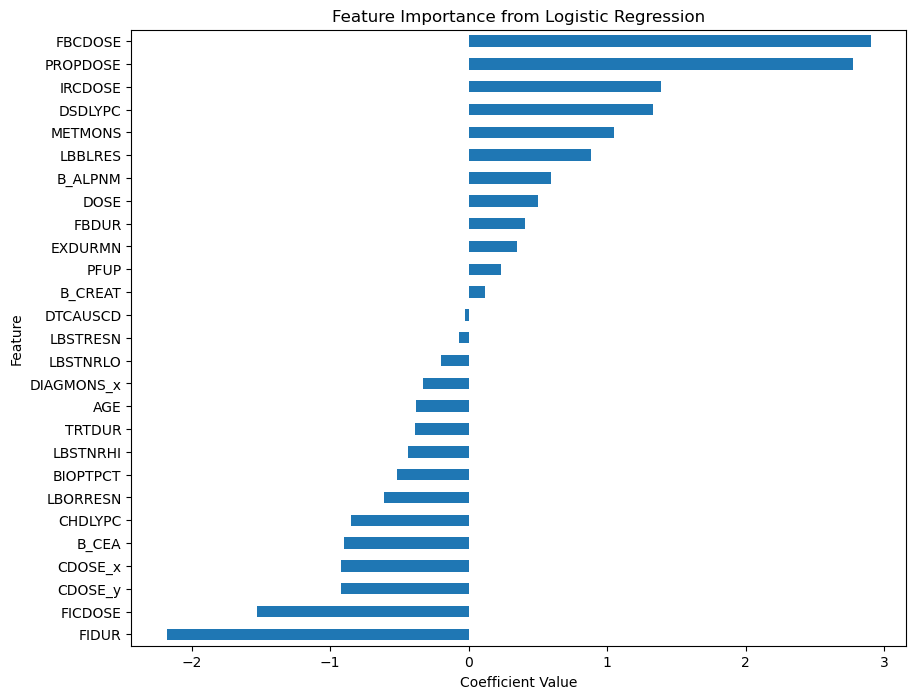

In [55]:
feature_importance.sort_values().plot(kind='barh', figsize=(10, 8))
plt.title('Feature Importance from Logistic Regression')
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.show()

# Hyperparameter

In [57]:
X=result[['IRCDOSE','TRTDUR','FICDOSE','LBORRESN','METMONS','B_CEA','LBSTRESN','PFUP','DOSE','B_CREAT','CDOSE_x','LBSTNRLO','FIDUR','FBDUR','FBCDOSE','B_ALPNM','EXDURMN','LBBLRES','CDOSE_y','DIAGMONS_x','LBSTNRHI','BIOPTPCT','DTCAUSCD','DSDLYPC','AGE','CHDLYPC','PROPDOSE']]
y=result[['LSSLD_Change']]
X.fillna(0,inplace=True)
y.fillna(0,inplace=True)

In [58]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [59]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
model13 = LogisticRegression(solver='liblinear')

In [60]:
param_grid = {
    'C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0], 
    'penalty': ['l1', 'l2']  
}

In [61]:
grid_search = GridSearchCV(estimator=model13, param_grid=param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train_scaled, y_train)

best_model = grid_search.best_estimator_

In [62]:
best_model.fit(X_train_scaled, y_train)

LogisticRegression(C=10.0, solver='liblinear')

In [63]:
y_test_pred = best_model.predict(X_test_scaled)

# Evaluate the best model on test data
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"Test Accuracy: {test_accuracy:.4f}")

print("\nConfusion Matrix on Test Data:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report on Test Data:")
print(classification_report(y_test, y_test_pred))

Test Accuracy: 0.8348

Confusion Matrix on Test Data:
[[ 95  30]
 [ 27 193]]

Classification Report on Test Data:
              precision    recall  f1-score   support

         0.0       0.78      0.76      0.77       125
         1.0       0.87      0.88      0.87       220

    accuracy                           0.83       345
   macro avg       0.82      0.82      0.82       345
weighted avg       0.83      0.83      0.83       345



In [64]:
y_train_pred = best_model.predict(X_train_scaled)

y_test_pred = best_model.predict(X_test_scaled)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")


Training Accuracy: 0.8469
Test Accuracy: 0.8348


# Feature Importance for Logistic Regression with Hyperameter

In [69]:
coefficients = best_model.coef_[0]
feature_importance = pd.Series(coefficients, index=X.columns)

In [74]:
print("Feature Importance Values:\n")
print(feature_importance.sort_values(ascending=False))

Feature Importance Values:

FBCDOSE       4.431087
PROPDOSE      3.578450
DSDLYPC       2.411553
FBDUR         2.235626
IRCDOSE       1.799768
METMONS       1.181935
LBBLRES       1.032873
B_ALPNM       0.676422
DOSE          0.606228
EXDURMN       0.360076
PFUP          0.181759
B_CREAT       0.086662
DTCAUSCD      0.002115
LBSTRESN     -0.047400
LBSTNRLO     -0.235317
AGE          -0.249540
DIAGMONS_x   -0.328444
LBSTNRHI     -0.424348
BIOPTPCT     -0.536421
LBORRESN     -0.661061
TRTDUR       -0.718212
CDOSE_x      -1.262889
CDOSE_y      -1.262889
B_CEA        -1.328617
CHDLYPC      -1.843622
FICDOSE      -2.529346
FIDUR        -4.215694
dtype: float64


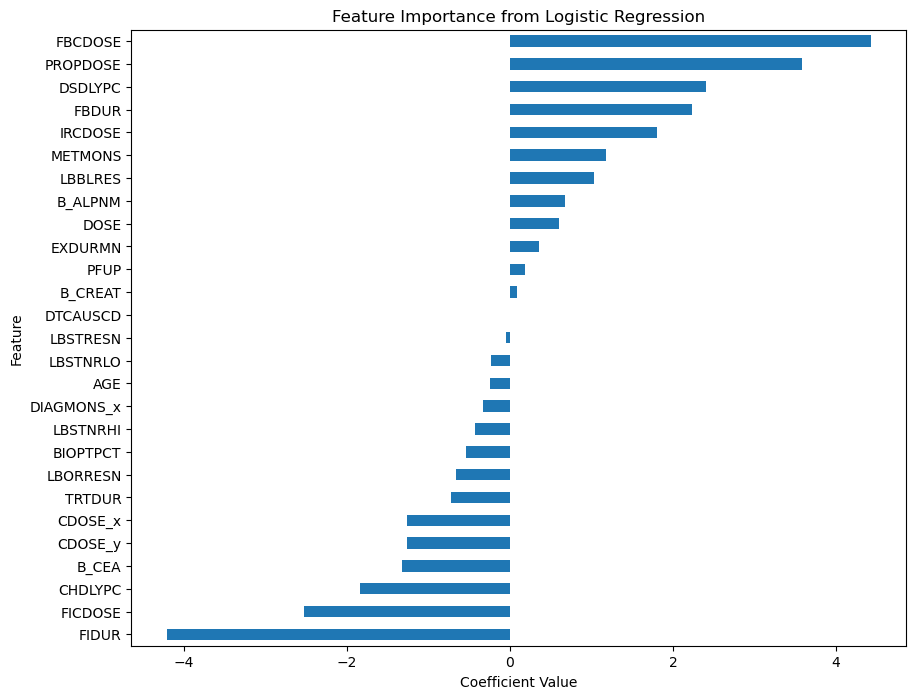

In [76]:
feature_importance.sort_values().plot(kind='barh', figsize=(10, 8))
plt.title('Feature Importance from Logistic Regression')
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.show()

# Elastic Net

In [86]:
X=result[['IRCDOSE','TRTDUR','FICDOSE','LBORRESN','METMONS','B_CEA','LBSTRESN','PFUP','DOSE','B_CREAT','CDOSE_x','LBSTNRLO','FIDUR','FBDUR','FBCDOSE','B_ALPNM','EXDURMN','LBBLRES','CDOSE_y','DIAGMONS_x','LBSTNRHI','BIOPTPCT','DTCAUSCD','DSDLYPC','AGE','CHDLYPC','PROPDOSE']]
y=result[['LSSLD_Change']]
X.fillna(0,inplace=True)
y.fillna(0,inplace=True)

In [94]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
param_grid = {
    'penalty': ['elasticnet'],
    'solver': ['saga'],
    'l1_ratio': [0.1, 0.5, 0.7, 0.9],  
    'C': [0.1, 1.0, 10.0]  
}

In [95]:
model14 = GridSearchCV(LogisticRegression(max_iter=1000), param_grid, cv=10, scoring='accuracy')

In [101]:
model14.fit(X_train_scaled, y_train)

GridSearchCV(cv=10, estimator=LogisticRegression(max_iter=1000),
             param_grid={'C': [0.1, 1.0, 10.0],
                         'l1_ratio': [0.1, 0.5, 0.7, 0.9],
                         'penalty': ['elasticnet'], 'solver': ['saga']},
             scoring='accuracy')

In [102]:
best_model = model14.best_estimator_
y_train_pred = best_model.predict(X_train_scaled)
y_test_pred = best_model.predict(X_test_scaled)

In [103]:
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Training Accuracy: 0.8469
Test Accuracy: 0.8348


In [104]:
cv_scores = cross_val_score(best_model, X_train_scaled, y_train, cv=5)
print(f"\nCross-validation scores: {cv_scores}")
print(f"Mean CV accuracy: {np.mean(cv_scores):.4f} (+/- {np.std(cv_scores):.4f})")


Cross-validation scores: [0.76449275 0.83333333 0.81884058 0.85454545 0.82545455]
Mean CV accuracy: 0.8193 (+/- 0.0299)


In [105]:
print("\nBest Parameters:")
print(model14.best_params_)


Best Parameters:
{'C': 1.0, 'l1_ratio': 0.1, 'penalty': 'elasticnet', 'solver': 'saga'}


In [106]:
print("\nClassification Report on Test Data:")
print(classification_report(y_test, y_test_pred))

print("\nConfusion Matrix on Test Data:")
print(confusion_matrix(y_test, y_test_pred))


Classification Report on Test Data:
              precision    recall  f1-score   support

         0.0       0.78      0.76      0.77       125
         1.0       0.87      0.88      0.87       220

    accuracy                           0.83       345
   macro avg       0.82      0.82      0.82       345
weighted avg       0.83      0.83      0.83       345


Confusion Matrix on Test Data:
[[ 95  30]
 [ 27 193]]


# Feature Importance for Logistic Regression for Elastic Net

In [115]:
feature_names = X.columns
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

In [117]:
feature_importance_df = feature_importance_df[feature_importance_df['Coefficient'] != 0]

# Sort features by absolute value of coefficients
feature_importance_df['Importance'] = feature_importance_df['Coefficient'].abs()
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

print("Feature Importances:")
print(feature_importance_df)


Feature Importances:
       Feature  Coefficient  Importance
14     FBCDOSE     2.972011    2.972011
26    PROPDOSE     2.787635    2.787635
12       FIDUR    -2.221414    2.221414
2      FICDOSE    -1.544242    1.544242
0      IRCDOSE     1.361456    1.361456
23     DSDLYPC     1.296189    1.296189
4      METMONS     1.051920    1.051920
18     CDOSE_y    -0.926291    0.926291
10     CDOSE_x    -0.926291    0.926291
5        B_CEA    -0.898595    0.898595
17     LBBLRES     0.871791    0.871791
25     CHDLYPC    -0.813461    0.813461
3     LBORRESN    -0.608227    0.608227
15     B_ALPNM     0.600215    0.600215
21    BIOPTPCT    -0.518339    0.518339
8         DOSE     0.501001    0.501001
20    LBSTNRHI    -0.435207    0.435207
24         AGE    -0.379489    0.379489
13       FBDUR     0.379439    0.379439
16     EXDURMN     0.348646    0.348646
19  DIAGMONS_x    -0.332112    0.332112
1       TRTDUR    -0.326931    0.326931
7         PFUP     0.235810    0.235810
11    LBSTNRLO    -

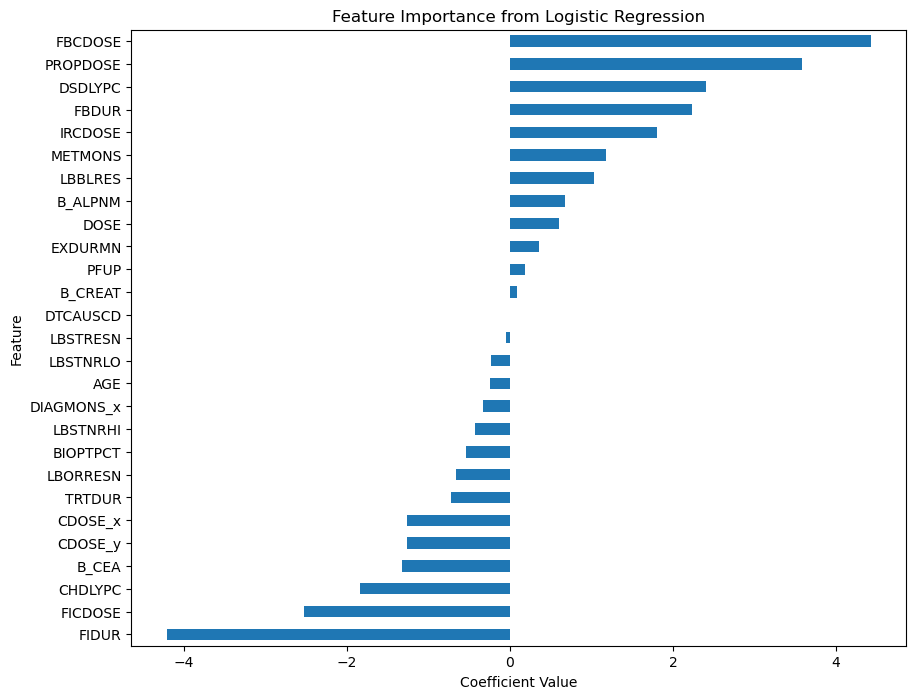

In [119]:
feature_importance.sort_values().plot(kind='barh', figsize=(10, 8))
plt.title('Feature Importance from Logistic Regression')
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.show()

# Regression with Linear,Decision Tree,Random Forest,Gadient Boosting,Support Vector and Neural Network

In [130]:
features=result[['IRCDOSE','TRTDUR','FICDOSE','LBORRESN','METMONS','B_CEA','LBSTRESN','PFUP','DOSE','B_CREAT','CDOSE_x','LBSTNRLO','FIDUR','FBDUR','FBCDOSE','B_ALPNM','EXDURMN','LBBLRES','CDOSE_y','DIAGMONS_x','LBSTNRHI','BIOPTPCT','DTCAUSCD','DSDLYPC','AGE','CHDLYPC','PROPDOSE']]
target=result[['LSSLD_Change']]

In [132]:
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest": RandomForestRegressor(),
    "Gradient Boosting": GradientBoostingRegressor(),
    "Support Vector Regression": make_pipeline(StandardScaler(), SVR()),
    "Neural Network": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=1000))
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    print(f"{name} - Mean Squared Error: {mse}, R² Score: {r2}")


Linear Regression - Mean Squared Error: 0.13738078966301437, R² Score: 0.4053909640130805
Decision Tree - Mean Squared Error: 0.0, R² Score: 1.0
Random Forest - Mean Squared Error: 0.0, R² Score: 1.0
Gradient Boosting - Mean Squared Error: 0.0014676544890398018, R² Score: 0.993647724525165
Support Vector Regression - Mean Squared Error: 0.009551963035412973, R² Score: 0.9586573672621808
Neural Network - Mean Squared Error: 0.00025482016564609976, R² Score: 0.9988970919921445


# Non Target Lesion

In [134]:
df2=pd.read_csv("C:\\Users\\dpree\\Desktop\\Kolate.AI\\1186\\Data\\Non_Target_Lesion_Dataset1.csv")

In [135]:
df2.columns

Index(['Unnamed: 0', 'SUBJID', 'AGE', 'SEXCD', 'TRTDOSE', 'ATRT', 'PRBEVCD',
       'PROXACDR', 'PROXAM', 'PFSCR', 'PFSCRV', 'PDLR', 'TRTDUR', 'B_METANM',
       'KRAS', 'TUMCAT', 'LIVRONLY', 'PFSCR.1', 'PDLR.1', 'B_ALPNM', 'B_CEA',
       'B_CREAT', 'CDOSE_x', 'IRCDOSE', 'FBDUR', 'FBCDOSE', 'FIDUR', 'FICDOSE',
       'DIAGMONS_x', 'METMONS', 'BIOPTPCT', 'BIOPRS', 'CDOSE_y', 'DSDLYPC',
       'CHDLYNM', 'CHDLYPC', 'PROPDOSE', 'CHRESPCD', 'CHDRSNCD', 'CHTERM_5 FU',
       'CHTERM_5-FU', 'CHTERM_CAPECITABINE', 'CHTERM_LEUCOVORIN',
       'CHTERM_OXALIPLATIN', 'CHANY_Y', 'DTCAUSCD', 'DIAGMONS_y', 'BIOPACPT',
       'BIOPCYTO', 'PFUP', 'KRASCD', 'EVALITT_Y', 'EXDURMN', 'ACTTRTCD',
       'DOSE', 'LBSTRESN', 'LBSTNRLO', 'LBSTNRHI', 'LBORRESN', 'LBBLRES',
       'LBBASE_N', 'LBBASE_Y', 'DOSREFDY', 'min_DOSREFDY', 'min_LSSLD',
       'max_DOSREFDY', 'max_LSSLD', 'LSSLD_Diff', 'Percentage_LSSLD_Change',
       'LSSLD_Change', 'LPSUM_x', 'OTANY_N', 'OTANY_Y', 'RAANY_N', 'RAANY_Y',
       'RSNEW

In [138]:
df2.shape

(71644, 80)

In [140]:
df2.head()

,Unnamed: 0,SUBJID,AGE,SEXCD,TRTDOSE,ATRT,PRBEVCD,PROXACDR,PROXAM,PFSCR,...,LPSUM_x,OTANY_N,OTANY_Y,RAANY_N,RAANY_Y,RSNEW_N,RSNEW_Y,SXANY_N,SXANY_Y,LPSUM_y
0,0,201001001,54.0,M,6.0,Panitumumab + FOLFIRI,1.0,1.0,Y,1.0,...,NaN,0,1,1,0,1,1,0,1,NaN
1,1,201001001,54.0,M,6.0,Panitumumab + FOLFIRI,1.0,1.0,Y,1.0,...,NaN,0,1,1,0,1,1,0,1,NaN
2,2,201001001,54.0,M,6.0,Panitumumab + FOLFIRI,1.0,1.0,Y,1.0,...,NaN,0,1,1,0,1,1,0,1,NaN
3,3,201001001,54.0,M,6.0,Panitumumab + FOLFIRI,1.0,1.0,Y,1.0,...,NaN,0,1,1,0,1,1,0,1,NaN
4,4,201001001,54.0,M,6.0,Panitumumab + FOLFIRI,1.0,1.0,Y,1.0,...,NaN,0,1,1,0,1,1,0,1,NaN


In [142]:
df2['LSSLD_Change'].unique()

array([0], dtype=int64)

# Conclusion:

LSSLD for Non-Target Lesion is 0 for all SUBJID, hence prediction won't make sense.